# 08. Huấn Luyện LSTM/GRU Dự Báo CGM (`rnn_glucose_lstm.pt`) & Q-Learning RL (`rl_qtable.npz`)
1. **LSTM & GRU (`RNNTemporalEngine`)**: Dự báo đường huyết liên tục CGM ở chân trời +30 phút và +60 phút từ 12 điểm đo gần nhất (cách nhau 15 phút). Artifact: `/notebook/model/rnn_glucose_lstm.pt`.
2. **Tabular Q-Learning (`DiabetesQLearningEngine`)**: Học bảng giá trị hành động $Q(s, a)$ trên 24 trạng thái lâm sàng và 4 bậc phác đồ điều trị kết hợp **ADA 2024 + QĐ 5481/BYT + Vinmec + Dược điển Long Châu**. Artifact: `/notebook/model/rl_qtable.npz`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.config import settings
from src.models.qlearning_treatment import ACTION_DESCRIPTIONS, DiabetesQLearningEngine
from src.models.rnn_temporal import MODEL_PATH, RNNTemporalEngine

rnn = RNNTemporalEngine()
history = [105, 112, 120, 132, 146, 159, 171, 182, 190, 196, 203, 210]
cgm_out = rnn.analyze_glucose_trajectory(history)
print(f"RNN Artifact: {MODEL_PATH.relative_to(ROOT)} | Dự báo +30p/+60p:", cgm_out["forecast"])
print(f"TIR (70-180): {cgm_out['tir_percentage']}% | TAR (>180): {cgm_out['tar_percentage']}% | GMI: {cgm_out['estimated_hba1c']}%")


RNN Artifact: notebook/model/rnn_glucose_lstm.pt | Dự báo +30p/+60p: [{'minutes': 15, 'glucose_mg_dl': 210.9}, {'minutes': 30, 'glucose_mg_dl': 205.4}, {'minutes': 45, 'glucose_mg_dl': 197.8}, {'minutes': 60, 'glucose_mg_dl': 189.9}]
TIR (70-180): 58.3% | TAR (>180): 41.7% | GMI: 7.22%


Đã lưu RL artifact: notebook/model/rl_qtable.npz


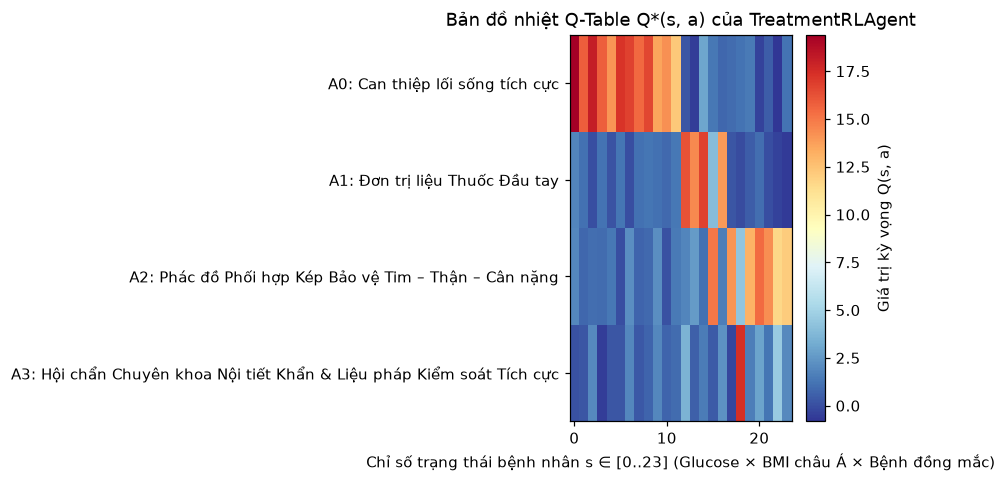

In [2]:
# Huấn luyện Q-Table RL & trực quan hóa Heatmap chính sách điều trị
rl = DiabetesQLearningEngine()
rl_path = settings.model_dir / "rl_qtable.npz"
np.savez_compressed(rl_path, q_table=rl.q_table)
print("Đã lưu RL artifact:", rl_path.relative_to(ROOT))

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(rl.q_table.T, aspect="auto", cmap="RdYlBu_r")
ax.set_yticks(range(4))
ax.set_yticklabels([f"A{i}: {a['name'].split('(')[0].strip()}" for i, a in enumerate(ACTION_DESCRIPTIONS)])
ax.set_xlabel("Chỉ số trạng thái bệnh nhân s ∈ [0..23] (Glucose × BMI châu Á × Bệnh đồng mắc)")
ax.set_title("Bản đồ nhiệt Q-Table Q*(s, a) của TreatmentRLAgent")
plt.colorbar(im, ax=ax, label="Giá trị kỳ vọng Q(s, a)")
plt.tight_layout()
